In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import time
import os
import random

import matplotlib.pyplot as plt

import numpy as np
import pandas as pd
import torch
import torch.optim as optim
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset

from torchvision import models

from sklearn.metrics import balanced_accuracy_score, f1_score, precision_score, confusion_matrix, ConfusionMatrixDisplay

DEVICE = torch.device("cuda")  # Try "cuda" to train on GPU
print(f"Training on {DEVICE}")

Training on cuda


In [ ]:
# Define the path to the dataset and the sequence length
NUM_CLIENTS_TRAIN = 6
NUM_CLIENTS_TEST = 2
NUM_CLASSES = 7
LEARNING_RATE=5e-3
LEARNING_RATE_STEP=5
LEARNING_RATE_GAMMA=0.75
WEIGHT_DECAY=1e-4
NUM_EPOCHS = 75
WINDOW_SIZE = 512
STRIDE = 256
ABSOLUTE = False
BATCH_SIZE = 64
NUM_CHANNELS = 6
PATIENCE = 15
PATH = '/content/drive/MyDrive/Mestrado/datasets/'

if(NUM_CHANNELS == 3):
    PROC_FILE_SUFIX = "rgb.pt"
    PROC_FILE_FOLDER = "/ProcessedFiles/PAMAP/"
    FILE_PREFIX = '3_CHANNELS'
elif(NUM_CHANNELS == 6):
    PROC_FILE_SUFIX = "rgb_withGyro.pt"
    PROC_FILE_FOLDER = "/ProcessedFiles/PAMAP/"
    FILE_PREFIX = '6_CHANNELS'

In [ ]:
# Load data from file
df = pd.read_csv(PATH+"/pamap2_processed.csv")

# Define the activities to keep
activities_to_keep = [
    "lying",
    "running",
    "sitting",
    "standing",
    "walking",
    "ascending stairs",
    "descending stairs"
]

# Filter the DataFrame
df = df[df["activity"].isin(activities_to_keep)]

# Map activities to integers if not already done
activity_mapping = {activity: idx for idx, activity in enumerate(df['activity'].unique())}
df['activity'] = df['activity'].map(activity_mapping)

# Split the dataset by subject_id
subject_ids = df['subject_id'].unique()
subject_ids

/tmp/ipython-input-48-4021627322.py:20: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['activity'] = df['activity'].map(activity_mapping)


array([8, 7, 6, 4, 5, 1, 2, 3])

In [ ]:
activity_mapping

{'lying': 0,
 'sitting': 1,
 'standing': 2,
 'ascending stairs': 3,
 'descending stairs': 4,
 'walking': 5,
 'running': 6}

In [ ]:
def print_unique_labels_from_files(directory, prefix="processed_user_", suffix="_rgb_withGyro.pt"):
    """
    Reads each processed file in the specified directory and prints the unique labels.

    Parameters:
    - directory: str, path where the .pt files are stored.
    - prefix: str, beginning pattern of the filenames to consider.
    - suffix: str, ending pattern of the filenames to consider.

    Returns:
    - None
    """
    directory = directory + PROC_FILE_FOLDER
    print(directory)
    for filename in os.listdir(directory):
        if filename.startswith(prefix) and filename.endswith(suffix):
            file_path = os.path.join(directory, filename)
            try:
                data = torch.load(file_path)
                labels = data['labels']
                unique_labels = torch.unique(labels).tolist()
                print(f"{filename}: Unique labels -> {unique_labels}")
            except Exception as e:
                print(f"Failed to read {filename}: {e}")

In [ ]:
print_unique_labels_from_files(PATH,prefix=f"PAMAP_processed_user_abs{ABSOLUTE}_{WINDOW_SIZE}_{STRIDE}")
#PAMAP_processed_user_abs{ABSOLUTE}_{WINDOW_SIZE}_{STRIDE}_{subject_id}_{PROC_FILE_SUFIX}

/content/drive/MyDrive/Mestrado/datasets//ProcessedFiles/PAMAP/
PAMAP_processed_user_absFalse_512_256_8_rgb_withGyro.pt: Unique labels -> [0, 1, 2, 3, 4, 5, 6]
PAMAP_processed_user_absFalse_512_256_7_rgb_withGyro.pt: Unique labels -> [0, 1, 2, 3, 4, 5, 6]
PAMAP_processed_user_absFalse_512_256_6_rgb_withGyro.pt: Unique labels -> [0, 1, 2, 3, 4, 5, 6]
PAMAP_processed_user_absFalse_512_256_4_rgb_withGyro.pt: Unique labels -> [0, 1, 2, 3, 4, 5]
PAMAP_processed_user_absFalse_512_256_5_rgb_withGyro.pt: Unique labels -> [0, 1, 2, 3, 4, 5, 6]
PAMAP_processed_user_absFalse_512_256_1_rgb_withGyro.pt: Unique labels -> [0, 1, 2, 3, 4, 5, 6]
PAMAP_processed_user_absFalse_512_256_2_rgb_withGyro.pt: Unique labels -> [0, 1, 2, 3, 4, 5, 6]
PAMAP_processed_user_absFalse_512_256_3_rgb_withGyro.pt: Unique labels -> [0, 1, 2, 3, 4, 5]


In [ ]:
class CustomDataset(Dataset):
    def __init__(self, processed_data_path):
        """
        Initialize the dataset with precomputed recurrence plots.

        Parameters:
        - processed_data_path: str, path to the preprocessed data file.
        """
        # Load the preprocessed data
        data = torch.load(processed_data_path)
        self.data = data['data'].float().permute(0, 3, 1, 2)
        self.labels = data['labels'].long()

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return {'data': self.data[idx], 'label': self.labels[idx]}

    def print_unique_labels(self):
        print(f"Unique labels: {self.labels.unique()}")


In [ ]:
def load_train_data():
    """
    Load test data from preprocessed recurrence plot files.

    Returns:
    - testloader: DataLoader for the test data.
    """
    try:
        train_clients = subject_ids[:NUM_CLIENTS_TRAIN]
        print(f"Train clients: {train_clients}")

        datasets = []
        for client_id in train_clients:
            # Construct the file path for the preprocessed data
            file_path = f"{PATH}{PROC_FILE_FOLDER}PAMAP_processed_user_abs{ABSOLUTE}_{WINDOW_SIZE}_{STRIDE}_{client_id}_{PROC_FILE_SUFIX}"
            try:
                # Create a dataset object for the client's preprocessed data
                dataset = CustomDataset(processed_data_path=file_path)
                datasets.append(dataset)
            except FileNotFoundError:
                print(f"Preprocessed file not found for client {client_id}: {file_path}")
                continue

        if not datasets:
            raise ValueError("No preprocessed data found for any test client.")
        # Concatenate all client datasets into one
        combined_dataset = torch.utils.data.ConcatDataset(datasets)

        labels = [sample['label'].item() for sample in combined_dataset]
        unique_ids = set(labels)
        print(f"Unique labels: {unique_ids}")

        # Create DataLoader
        trainloader = DataLoader(combined_dataset, batch_size=BATCH_SIZE, shuffle=True)
        return trainloader

    except Exception as e:
        print(f"An error occurred in load_train_data: {e}")
        return None


In [ ]:
#for i in range(1,25):
train_loader = load_train_data()
batch = next(iter(train_loader))
data, labels = batch["data"], batch["label"]
x_shape = data.shape
y_shape = labels.shape
x_shape, y_shape

Train clients: [8 7 6 4 5 1]
Unique labels: {0, 1, 2, 3, 4, 5, 6}


(torch.Size([64, 6, 128, 128]), torch.Size([64]))

In [ ]:
def show_random_image(train_loader):
    """
    Displays two images (derived from the 6-channel input) from the given train_loader.

    Args:
        train_loader: DataLoader object containing the training data.
    """
    # Get a random batch from the loader
    batch = next(iter(train_loader))
    data, labels = batch["data"], batch["label"]

    # Select a random index within the batch
    random_index = random.randint(0, data.size(0) - 1)
    random_image = data[random_index]  # Extract the 6-channel image
    label = labels[random_index].item()  # Extract the label

    # Split the 6-channel image into two 3-channel images
    image1 = random_image[:3, :, :]  # First 3 channels
    # Rearrange image dimensions from [C, H, W] to [H, W, C]
    image1_to_plot = image1.permute(1, 2, 0).cpu().numpy()
    # Normalize the images to [0, 1] for visualization
    image1_to_plot = (image1_to_plot - image1_to_plot.min()) / (image1_to_plot.max() - image1_to_plot.min())

    if(NUM_CHANNELS == 6):
        image2 = random_image[3:, :, :]  # Last 3 channels
        image2_to_plot = image2.permute(1, 2, 0).cpu().numpy()
        image2_to_plot = (image2_to_plot - image2_to_plot.min()) / (image2_to_plot.max() - image2_to_plot.min())

    # Plot the images side by side
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    axes[0].imshow(image1_to_plot)
    axes[0].set_title("First Image")
    axes[0].axis("off")

    if(NUM_CHANNELS == 6):
        axes[1].imshow(image2_to_plot)
        axes[1].set_title("Second Image")
        axes[1].axis("off")

    plt.suptitle(f"Label: {label}")
    plt.show()

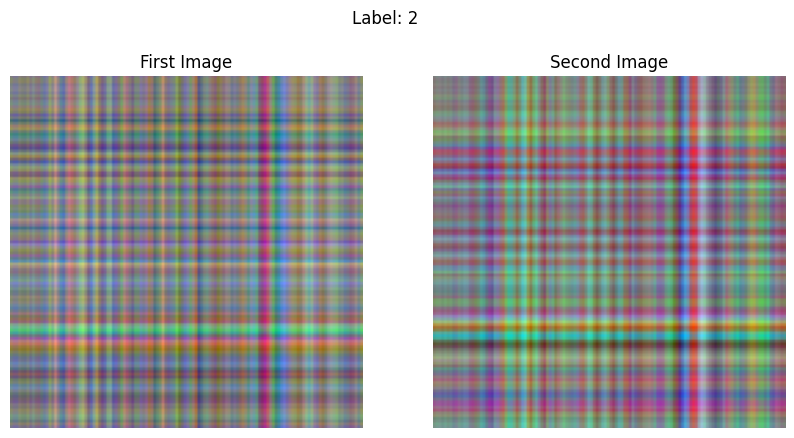

In [ ]:
show_random_image(train_loader)

In [ ]:
def load_test_data():
    """
    Load test data from preprocessed recurrence plot files.

    Returns:
    - testloader: DataLoader for the test data.
    """
    try:
        test_clients = subject_ids[-NUM_CLIENTS_TEST:]
        print(f"Test clients: {test_clients}")

        datasets = []

        for client_id in test_clients:
            # Construct the file path for the preprocessed data
            file_path = f"{PATH}{PROC_FILE_FOLDER}PAMAP_processed_user_abs{ABSOLUTE}_{WINDOW_SIZE}_{STRIDE}_{client_id}_{PROC_FILE_SUFIX}"
            try:
                # Create a dataset object for the client's preprocessed data
                dataset = CustomDataset(processed_data_path=file_path)
                datasets.append(dataset)
            except FileNotFoundError:
                print(f"Preprocessed file not found for client {client_id}: {file_path}")
                continue

        if not datasets:
            raise ValueError("No preprocessed data found for any test client.")

        # Concatenate all client datasets into one
        combined_dataset = torch.utils.data.ConcatDataset(datasets)
        labels = [sample['label'].item() for sample in combined_dataset]
        unique_ids = set(labels)
        print(f"Unique labels: {unique_ids}")

        # Create DataLoader
        testloader = DataLoader(combined_dataset, batch_size=BATCH_SIZE, shuffle=False)

        return testloader

    except Exception as e:
        print(f"An error occurred in load_test_data: {e}")
        return None


In [ ]:
test_loader = load_test_data()
batch = next(iter(test_loader))
data, labels = batch["data"], batch["label"]
x_shape = data.shape
y_shape = labels.shape
x_shape, y_shape

Test clients: [2 3]
Unique labels: {0, 1, 2, 3, 4, 5, 6}


(torch.Size([64, 6, 128, 128]), torch.Size([64]))

In [ ]:
import timm
class ResNet(nn.Module):
    def __init__(self, num_classes, num_channels=4):
        super().__init__()
        self.backbone = timm.create_model(
            'resnetv2_101x1_bit.goog_in21k_ft_in1k',
            pretrained=True,
            in_chans=num_channels,
            num_classes=num_classes
        )

    def forward(self, x):
        return self.backbone(x)

In [ ]:
class ModifiedMobileNetV2(nn.Module):
    def __init__(self, num_classes):
        super(ModifiedMobileNetV2, self).__init__()
        # Load MobileNetV2 with pretrained weights
        self.base_model = models.mobilenet_v2(weights='DEFAULT')
        #self.base_model.load_state_dict(torch.load(f"./mobilenet_v2-b0353104.pth"))

        # Modify the input layer to handle 4 channels instead of 3
        self.base_model.features[0][0] = nn.Conv2d(
            in_channels=NUM_CHANNELS, out_channels=32, kernel_size=3, stride=2, padding=1, bias=False
        )

        # Replace the final layer to match the number of classes
        self.base_model.classifier[1] = nn.Linear(self.base_model.last_channel, num_classes)

    def forward(self, x):
        return self.base_model(x)

In [ ]:
def evaluate(loader, model):
    """
    Evaluate the model on the given dataset.

    Parameters:
    - loader: DataLoader containing the evaluation dataset.
    - model: Trained PyTorch model.

    Returns:
    - balanced_acc: Balanced accuracy of the model.
    - f1: F1 score of the model.
    - precision: Precision of the model.
    - conf_matrix: Normalized confusion matrix.
    """
    model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for batch in loader:
            data, labels = batch["data"].to(DEVICE), batch["label"].to(DEVICE)
            outputs = model(data)
            _, predicted = torch.max(outputs.data, 1)
            all_preds.extend(predicted.cpu().numpy())  # Transform to numpy to add to the full list of predictions
            all_labels.extend(labels.cpu().numpy())

    balanced_acc = balanced_accuracy_score(all_labels, all_preds) * 100
    f1 = f1_score(all_labels, all_preds, average='weighted') * 100
    precision = precision_score(all_labels, all_preds, average='weighted', zero_division=0) * 100
    conf_matrix = confusion_matrix(all_labels, all_preds, normalize='true')

    return balanced_acc, f1, precision, conf_matrix

In [ ]:
from torch.optim.lr_scheduler import StepLR
def train(model, train_loader, test_loader, criterion, optimizer, num_epochs, patience=5, verbose=False):
    """
    Train the model with early stopping and evaluate it at each epoch.

    Parameters:
    - model: PyTorch model to be trained.
    - train_loader: DataLoader object containing the training data.
    - test_loader: DataLoader object containing the test data.
    - criterion: Loss function.
    - optimizer: Optimization algorithm.
    - num_epochs: Number of epochs to train the model.
    - patience: Number of epochs to wait before early stopping if no improvement.
    - verbose: Boolean indicating whether to print detailed information during training.

    Returns:
    - train_losses: List of training losses for each epoch.
    - train_metrics: Dictionary containing training metrics (accuracy, F1 score, precision, confusion matrix).
    - test_metrics: Dictionary containing test metrics (accuracy, F1 score, precision, confusion matrix).
    """
    total_training_time = 0
    best_test_acc = 0
    epochs_no_improve = 0
    train_metrics = {'accuracy': [], 'f1score': [], 'precision': [], 'conf_matrix': None}
    test_metrics = {'accuracy': [], 'f1score': [], 'precision': [], 'conf_matrix': None}
    train_losses = []


    scheduler = StepLR(optimizer, step_size=LEARNING_RATE_STEP, gamma=LEARNING_RATE_GAMMA)
    for epoch in range(num_epochs):
        model.train()
        start_epoch_time = time.time()
        total_loss = 0

        for batch in train_loader:
            data, labels = batch["data"].to(DEVICE), batch["label"].to(DEVICE)
            optimizer.zero_grad()
            outputs = model(data)
            # Print shapes for debugging
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()

        avg_loss = total_loss / len(train_loader)
        end_epoch_time = time.time()
        epoch_time = end_epoch_time - start_epoch_time
        total_training_time += epoch_time
        train_losses.append(avg_loss)

        # Evaluate on training and test data
        train_acc, train_f1, train_precision, train_conf_matrix = evaluate(train_loader, model)
        test_acc, test_f1, test_precision, test_conf_matrix = evaluate(test_loader, model)

        # Store the metrics
        train_metrics['accuracy'].append(train_acc)
        train_metrics['f1score'].append(train_f1)
        train_metrics['precision'].append(train_precision)
        test_metrics['accuracy'].append(test_acc)
        test_metrics['f1score'].append(test_f1)
        test_metrics['precision'].append(test_precision)

        # Check for the best accuracy and update early stopping criteria
        if test_acc > best_test_acc:
            best_test_acc = test_acc
            train_metrics['conf_matrix'] = train_conf_matrix
            test_metrics['conf_matrix'] = test_conf_matrix
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1

        if verbose:
            print(f'Epoch [{epoch+1}/{num_epochs}], Train Loss: {avg_loss:.4f}, Train Accuracy: {train_acc:.2f}%, '
                  f'Test Accuracy: {test_acc:.2f}%, Time: {epoch_time:.2f} seconds')

        # Early stopping
        if patience != 0 and epochs_no_improve == patience:
            print(f'Early stopping at epoch {epoch+1} with best test accuracy: {best_test_acc:.2f}%')
            break

        scheduler.step()


    if verbose:
        print(f'Total Training Time: {total_training_time:.2f} seconds')

    return train_losses, train_metrics, test_metrics

In [ ]:
def freeze_and_clean_layers(model, unfrozen_layers):
    frozen = 0

    # Freeze all layers in the model initially
    for param in model.base_model.parameters():
        param.requires_grad = False

    # Unfreeze and clean the classifier layers first
    for layer in reversed(list(model.base_model.classifier.children())):
        if frozen < unfrozen_layers:
            for param in layer.parameters():
                param.requires_grad = True
                if hasattr(layer, 'reset_parameters'):
                    layer.reset_parameters()  # Clean weights
            frozen += 1

    # Unfreeze and clean the feature layers next
    for layer in reversed(list(model.base_model.features.children())):
        if frozen < unfrozen_layers:
            for param in layer.parameters():
                param.requires_grad = True
                if hasattr(layer, 'reset_parameters'):
                    layer.reset_parameters()  # Clean weights
            frozen += 1


In [ ]:
model = ResNet(NUM_CLASSES, NUM_CHANNELS).to(DEVICE)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
# UNFROZEN_LAYERS = len(list(model.base_model.parameters())) * 0.5
# freeze_and_clean_layers(model, UNFROZEN_LAYERS)

In [ ]:
train_losses, train_metrics, test_metrics = train(
    model=model,
    train_loader=train_loader,
    test_loader=test_loader,
    criterion=criterion,
    optimizer=optimizer,
    num_epochs=NUM_EPOCHS,
    patience=PATIENCE,
    verbose=True
)

print("Training complete.")

Epoch [1/75], Train Loss: 3.9814, Train Accuracy: 14.56%, Test Accuracy: 14.95%, Time: 15.55 seconds
Epoch [2/75], Train Loss: 1.9638, Train Accuracy: 15.28%, Test Accuracy: 14.57%, Time: 15.12 seconds
Epoch [3/75], Train Loss: 1.8490, Train Accuracy: 21.63%, Test Accuracy: 22.50%, Time: 14.86 seconds
Epoch [4/75], Train Loss: 1.7027, Train Accuracy: 24.17%, Test Accuracy: 24.37%, Time: 14.99 seconds
Epoch [5/75], Train Loss: 1.5186, Train Accuracy: 43.56%, Test Accuracy: 41.87%, Time: 15.11 seconds
Epoch [6/75], Train Loss: 1.2564, Train Accuracy: 43.65%, Test Accuracy: 42.43%, Time: 15.11 seconds
Epoch [7/75], Train Loss: 1.1320, Train Accuracy: 45.82%, Test Accuracy: 45.59%, Time: 15.01 seconds
Epoch [8/75], Train Loss: 0.9474, Train Accuracy: 57.06%, Test Accuracy: 50.48%, Time: 15.01 seconds
Epoch [9/75], Train Loss: 0.8870, Train Accuracy: 55.54%, Test Accuracy: 47.13%, Time: 15.10 seconds
Epoch [10/75], Train Loss: 0.7566, Train Accuracy: 65.28%, Test Accuracy: 54.21%, Time: 15.

In [ ]:
print(f"Best Test Accuracy: {test_metrics['accuracy'][-PATIENCE-1]:.2f}%")
print(f"Best Test F1 Score: {test_metrics['f1score'][-PATIENCE-1]:.2f}%")
print(f"Best Test Precision: {test_metrics['precision'][-PATIENCE-1]:.2f}%")

Best Test Accuracy: 72.86%
Best Test F1 Score: 70.63%
Best Test Precision: 71.23%


In [ ]:

metrics_data = {
    'constants': {
        'DATASET': PATH,
        'NUM_CLIENTS': NUM_CLIENTS_TRAIN,
        'NUM_CLASSES': NUM_CLASSES,
        'WINDOW_SIZE': WINDOW_SIZE,
        'STRIDE': STRIDE,
        'ABSOLUTE': ABSOLUTE,
        'PATIENCE': PATIENCE,
        'LEARNING_RATE': LEARNING_RATE,
        'LEARNING_RATE_STEP': LEARNING_RATE_STEP,
        'LEARNING_RATE_GAMMA': LEARNING_RATE_GAMMA,
        'NUM_EPOCHS': NUM_EPOCHS,
        'BATCH_SIZE': BATCH_SIZE,
        'NUM_CHANNELS': NUM_CHANNELS,

        'LABEL_NAMES': activity_mapping,
        'BEST_ACCURACY': test_metrics['accuracy'][-PATIENCE-1],
        'BEST_F1': test_metrics['f1score'][-PATIENCE-1],
        'BEST_PRECISION': test_metrics['precision'][-PATIENCE-1]
    },
    'train_losses': train_losses,
    'train_metrics': train_metrics,
    'test_metrics': test_metrics
}



In [ ]:
def convert_to_serializable(data):
    if isinstance(data, np.ndarray):
        return data.tolist()  # Convert NumPy array to list
    if isinstance(data, dict):
        return {key: convert_to_serializable(value) for key, value in data.items()}
    if isinstance(data, list):
        return [convert_to_serializable(item) for item in data]
    return data  # Return the data as is if it's not a NumPy array or a dict/list

In [ ]:
from datetime import datetime
import json
# Generate a datetime string for the filename
datetime_str = datetime.now().strftime("%Y%m%d_%H%M%S")

# Save to JSON file
filename = f'/content/drive/MyDrive/Mestrado/results/Centralized/RGB/recurrence_mobilenet_pamap_training_metrics_{datetime_str}.json'
with open(filename, 'w') as f:
    json.dump(convert_to_serializable(metrics_data), f, indent=4)

In [ ]:
def plot_metrics(train, test, title, metric):
    # summarize history for accuracy
    plt.plot(train)
    plt.plot(test)
    plt.grid()
    plt.title(title)
    plt.ylabel(metric)
    plt.xlabel('Epoch')
    plt.legend(['Train', 'Validation'], loc='best')
    plt.show()

In [ ]:
def plot_loss(loss, title, metric='Loss'):
    # summarize history for accuracy
    plt.plot(loss)
    plt.grid()
    plt.title(title)
    plt.ylabel(metric)
    plt.xlabel('Epoch')
    plt.legend(['Train'], loc='best')
    plt.show()

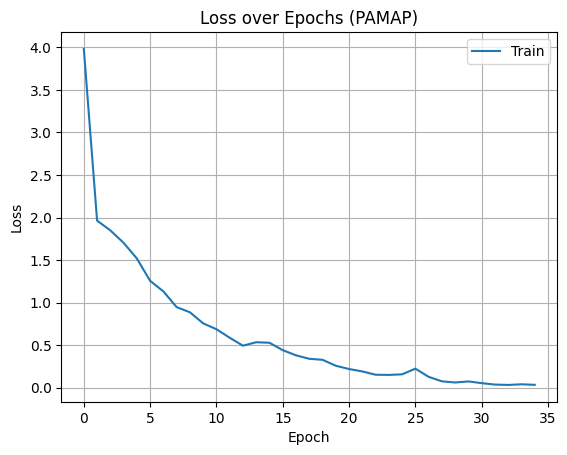

In [ ]:
plot_loss(train_losses, 'Loss over Epochs (PAMAP)', 'Loss')

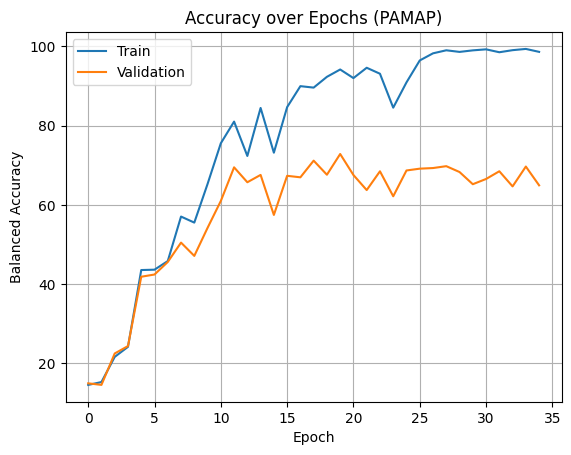

In [ ]:
plot_metrics(train_metrics['accuracy'], test_metrics['accuracy'], 'Accuracy over Epochs (PAMAP)', 'Balanced Accuracy')

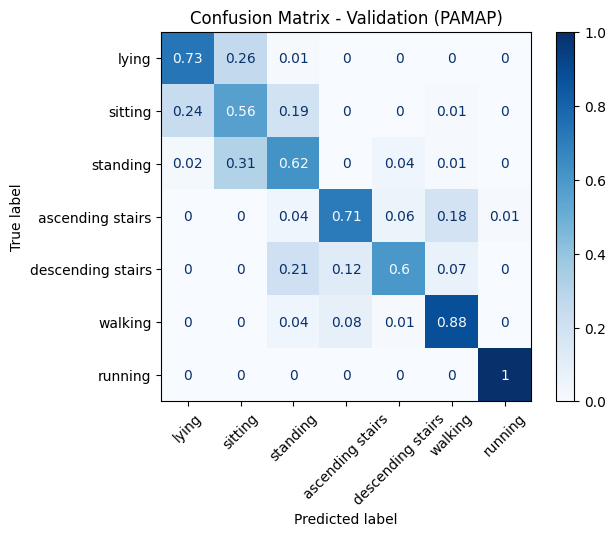

In [ ]:
disp = ConfusionMatrixDisplay(confusion_matrix=test_metrics['conf_matrix'].round(2), display_labels=activity_mapping)
disp.plot(cmap='Blues')
plt.title('Confusion Matrix - Validation (PAMAP)')
plt.xticks(rotation=45)
plt.show()